In [1]:
import numpy as np
import pandas as pd
import config
import matplotlib.pyplot as plt
# from scipy.stats import shapiro
# from scipy.stats import kruskal

from get_data import DataLoader

# Load data
DataLoader = DataLoader(config.DATA_PATH)
df = DataLoader.load_data()

df_2018exp = df[df['year']==2018].copy()
df_2018exp = df_2018exp[['who_region', 'pm25_concentration']].dropna()

In [2]:
print(df_2018exp.who_region.unique())

['4_Eur' '2_Amr' '5_Emr' '3_Sear' '1_Afr' '7_NonMS']


Categories from Assignment 1

In [3]:
df_2018exp.loc[(df_2018exp['pm25_concentration'] >= 30), 'pm25_cats'] = '(6) 30 +'
df_2018exp.loc[(df_2018exp['pm25_concentration'] >= 25) & (df_2018exp['pm25_concentration'] < 30), 'pm25_cats'] = '(5) 25 - 30'
df_2018exp.loc[(df_2018exp['pm25_concentration'] >= 15) & (df_2018exp['pm25_concentration'] < 25), 'pm25_cats'] = '(4) 15 - 25'
df_2018exp.loc[(df_2018exp['pm25_concentration'] >= 10) & (df_2018exp['pm25_concentration'] < 15), 'pm25_cats'] = '(3) 10 - 15'
df_2018exp.loc[(df_2018exp['pm25_concentration'] >=  5) & (df_2018exp['pm25_concentration'] < 10), 'pm25_cats'] =  '(2) 5 - 10'
df_2018exp.loc[(df_2018exp['pm25_concentration'] <   5), 'pm25_cats'] = '(1) 5 -'


df_2018exp.to_excel('checkq5.xlsx')

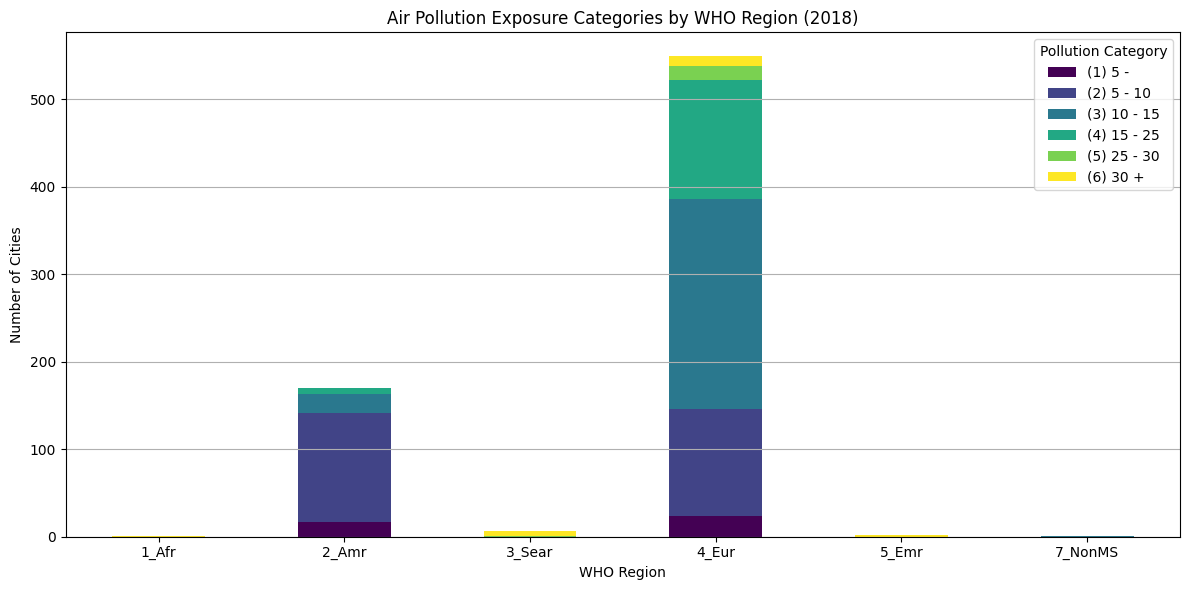

In [4]:
df_cross = pd.crosstab(df_2018exp['who_region'], df_2018exp['pm25_cats'])
df_cross.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='viridis')

# Plot decorations
plt.title('Air Pollution Exposure Categories by WHO Region (2018)')
plt.xlabel('WHO Region')
plt.ylabel('Number of Cities')
plt.xticks(rotation=0)
plt.legend(title='Pollution Category')
plt.grid(axis='y')
plt.tight_layout()

plt.savefig('q5_bar_pm25_region.png', dpi=300, bbox_inches='tight')
plt.show()


In [5]:
df_crossl = df_cross
df_crossl.loc['Total'] = df_crossl.sum()
df_crossl['Total'] = df_crossl.sum(axis=1)
print(df_crossl.to_latex(header=True, float_format="%.0f", escape=False))

\begin{tabular}{lrrrrrrr}
\toprule
pm25_cats & (1) 5 - & (2) 5 - 10 & (3) 10 - 15 & (4) 15 - 25 & (5) 25 - 30 & (6) 30 + & Total \\
who_region &  &  &  &  &  &  &  \\
\midrule
1_Afr & 0 & 0 & 0 & 0 & 0 & 1 & 1 \\
2_Amr & 17 & 124 & 22 & 7 & 0 & 0 & 170 \\
3_Sear & 0 & 0 & 0 & 0 & 1 & 5 & 6 \\
4_Eur & 24 & 122 & 240 & 136 & 16 & 11 & 549 \\
5_Emr & 0 & 0 & 0 & 0 & 0 & 2 & 2 \\
7_NonMS & 0 & 0 & 1 & 0 & 0 & 0 & 1 \\
Total & 41 & 246 & 263 & 143 & 17 & 19 & 729 \\
\bottomrule
\end{tabular}

